# Лабораторна робота №4: Генерування зображень за допомогою Stable Diffusion
## Частина 1: Вхідні зображення, архітектура Image-to-Image та базовий пайплайн

**Дисципліна:** Нейромережеві технології і системи  
**Тема:** Генерування зображень за допомогою Stable Diffusion  
**Варіант:** №2 — Image-to-Image (SD/SDXL)  
**Модель:** `stable-diffusion-v1-5/stable-diffusion-v1-5` (FP16 + Model CPU Offload)  
**Апаратне забезпечення:** NVIDIA GeForce RTX 3050 Laptop GPU (4 ГБ VRAM)  

---

### Мета першого етапу:
1. Дослідити теоретичні відмінності між Text-to-Image та Image-to-Image у латентних дифузійних моделях (LDM).
2. Провести діагностику обчислювального середовища (PyTorch з апаратним прискоренням CUDA, Diffusers, Transformers, стан VRAM та RAM).
3. Підготувати, перевірити та задокументувати 3 оригінальні вхідні цифрові зображення різних сюжетів (приморський маяк, кафе з велосипедом, інтер'єр старовинної бібліотеки).
4. Завантажити та налаштувати спеціалізований пайплайн `StableDiffusionImg2ImgPipeline` із оптимізацією використання пам'яті для 4 ГБ VRAM (`enable_model_cpu_offload`).
5. Виконати базове Image-to-Image перетворення для кожного з трьох сюжетів при фіксованому baseline-наборі параметрів (`seed=42`, `strength=0.6`, `CFG=7.5`, `steps=30`).
6. Зберегти вихідні зображення у високій якості та сформувати повні метадані кожного запуску.

## 1. Теоретичні засади технології Image-to-Image у Stable Diffusion

### 1.1 Відмінність Image-to-Image від Text-to-Image
У класичному режимі **Text-to-Image** генерація стартує з чистого випадкового гаусового шуму $z_T \sim \mathcal{N}(0, I)$ у латентному просторі, тобто модель не має жодної початкової геометрії, окрім текстового промпта.

У режимі **Image-to-Image (Img2Img)** початковою точкою є вже існуюче зображення $x_0 \in \mathbb{R}^{H \times W \times 3}$. Процес складається з таких фаз:
1. **Латентне кодування (VAE Encoding):** Вхідне піксельне зображення стискається автокодувальником (VAE Encoder $\mathcal{E}$) у низьковимірний латентний простір:
   $$z_0 = \mathcal{E}(x_0), \quad z_0 \in \mathbb{R}^{4 \times \frac{H}{8} \times \frac{W}{8}}$$
   Для зображення $512 \times 512$ розмір латентного представлення складає $4 \times 64 \times 64$.
2. **Часткове зашумлення та розрахунок таймстепів (Forward Diffusion / Timesteps calculation):**
   У бібліотеці Hugging Face Diffusers (клас `StableDiffusionImg2ImgPipeline`) кількість та індекси активних кроків денойзингу розраховуються відповідно до параметра сили перетворення $\text{strength} \in [0, 1]$:
   $$\text{init\_timestep} = \min(\lfloor \text{num\_inference\_steps} \times \text{strength} \rfloor, \text{num\_inference\_steps})$$
   $$t_{\text{start}} = \max(\text{num\_inference\_steps} - \text{init\_timestep}, 0)$$
   $$\text{timesteps} = \text{scheduler.timesteps}[t_{\text{start}} \times \text{scheduler.order} : ]$$
   Початковий шум додається до латентного вектора $z_0$ відповідно до найбільшого залишкового кроку $t_{\text{latent}} = \text{timesteps}[0]$:
   $$z_{t_{\text{latent}}} = \sqrt{\bar{\alpha}_{t_{\text{latent}}}} z_0 + \sqrt{1 - \bar{\alpha}_{t_{\text{latent}}}} \epsilon, \quad \epsilon \sim \mathcal{N}(0, I)$$
   Фактична кількість виконаних ітерацій UNet складає $\text{actual\_steps} = \text{num\_inference\_steps} - t_{\text{start}} = \text{init\_timestep}$.
3. **Кероване зворотне знешумлення (Reverse Denoising Process):** Починаючи не з $t=T$, а саме з $t=t_{\text{latent}}$, модель UNet ітеративно передбачає шум, спрямовуючи генерацію вектором текстового промпта $c$ та масштабом Classifier-Free Guidance (CFG):
   $$\hat{\epsilon} = \epsilon_\theta(z_t, \emptyset) + s \cdot (\epsilon_\theta(z_t, c) - \epsilon_\theta(z_t, \emptyset))$$
   де $s$ — коефіцієнт Classifier-Free Guidance (CFG, $\text{guidance\_scale}$).
4. **Латентне декодування (VAE Decoding):** Очищений вектор $z_0^*$ декодується VAE Decoder $\mathcal{D}$ назад у піксельний простір: $x^* = \mathcal{D}(z_0^*)$.

## 2. Діагностика апаратного та програмного середовища

In [1]:
import sys
import os
import platform
import time
import hashlib
from pathlib import Path

import torch
import diffusers
import transformers
import accelerate
import PIL
from PIL import Image
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print(f"Python version:      {platform.python_version()}")
print(f"PyTorch version:     {torch.__version__}")
print(f"CUDA Available:      {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device:          {torch.cuda.get_device_name(0)}")
    total_vram = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f"Total VRAM:          {total_vram:.2f} GB")
print(f"Diffusers version:   {diffusers.__version__}")
print(f"Transformers vers.:  {transformers.__version__}")
print(f"Accelerate version:  {accelerate.__version__}")
print(f"Pillow version:      {PIL.__version__}")

# Перевірка обмеження пам'яті для 4 ГБ VRAM
assert torch.cuda.is_available(), "Потрібен GPU із підтримкою CUDA для виконання генерації!"


C:\Users\Eclipse\PycharmProjects\neural-network-technologies-and-systems\max\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python version:      3.12.6
PyTorch version:     2.6.0+cu124
CUDA Available:      True
GPU Device:          NVIDIA GeForce RTX 3050 Laptop GPU
Total VRAM:          4.00 GB
Diffusers version:   0.41.0
Transformers vers.:  5.20.2
Accelerate version:  1.15.0
Pillow version:      12.3.0


Відповідно до методичних вказівок варіанта №2, підготовлено 3 незалежні структуровані вхідні зображення з роздільною здатністю $512 \times 512$:
1. **01_coastal_lighthouse.png** — пейзаж із чітким центральним об'єктом (маяк на скелястому узбережжі, океан, вечірнє небо).
2. **02_cafe_bicycle.png** — урбаністичний сюжет із вираженими геометричними лініями (велосипед біля літнього кафе, бруківка, арка).
3. **03_library_interior.png** — інтер'єр із багатою просторовою перспективою та ритмічними повтореннями (книжкові полиці, тепле світло, геометрія зали).

Знайдено вхідних зображень: 3
=== РЕЗУЛЬТАТИ АУДИТУ ВХІДНИХ ЗОБРАЖЕНЬ ===
                 filename resolution channels  file_size_kb              sha256
01_coastal_lighthouse.png    512x512      RGB          6.16 f71f5d9c045852eb...
      02_cafe_bicycle.png    512x512      RGB          8.41 f4bc1420d0125328...
  03_library_interior.png    512x512      RGB          6.13 9f72de9e37128dab...


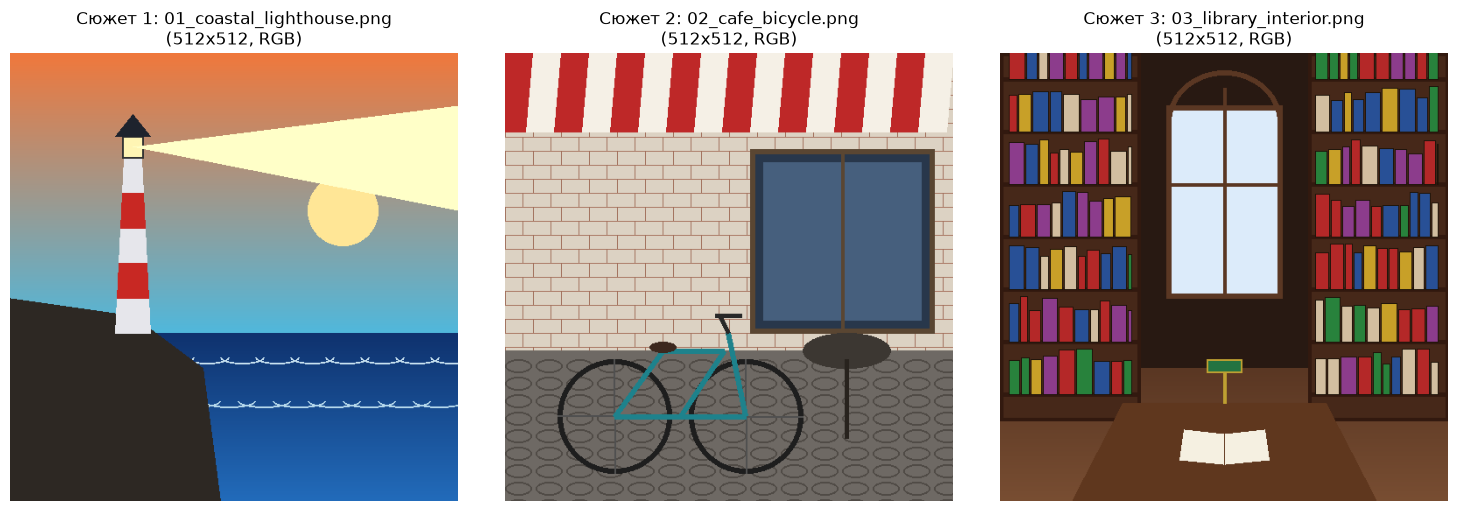

Огляд вхідних зображень збережено у ..\outputs\figures\input_images_overview.png


In [2]:
INPUTS_DIR = Path("../inputs").resolve()
assert INPUTS_DIR.exists(), f"Директорія {INPUTS_DIR} не існує!"

input_files = sorted(list(INPUTS_DIR.glob("*.png")))
print(f"Знайдено вхідних зображень: {len(input_files)}")

input_audit_records = []
loaded_images = {}

for p in input_files:
    img = Image.open(p)
    raw_bytes = p.read_bytes()
    sha256 = hashlib.sha256(raw_bytes).hexdigest()
    
    loaded_images[p.name] = img
    
    input_audit_records.append({
        "filename": p.name,
        "resolution": f"{img.size[0]}x{img.size[1]}",
        "channels": img.mode,
        "file_size_kb": round(len(raw_bytes) / 1024, 2),
        "sha256": sha256[:16] + "...",
        "full_sha256": sha256
    })

df_inputs = pd.DataFrame(input_audit_records)
print("=== РЕЗУЛЬТАТИ АУДИТУ ВХІДНИХ ЗОБРАЖЕНЬ ===")
print(df_inputs[["filename", "resolution", "channels", "file_size_kb", "sha256"]].to_string(index=False))

# Візуалізація трьох оригінальних сюжетів
out_figures = Path("../outputs/figures")
out_figures.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(15, 5))
for idx, (fname, img) in enumerate(loaded_images.items(), 1):
    plt.subplot(1, 3, idx)
    plt.imshow(img)
    plt.title(f"Сюжет {idx}: {fname}\n({img.size[0]}x{img.size[1]}, {img.mode})")
    plt.axis("off")

plt.tight_layout()
input_fig_path = out_figures / "input_images_overview.png"
plt.savefig(input_fig_path, dpi=300)
plt.show()
print(f"Огляд вхідних зображень збережено у {input_fig_path}")


## 4. Ініціалізація `StableDiffusionImg2ImgPipeline`

Для забезпечення стабільної роботи без помилок вичерпання відеопам'яті (Out-Of-Memory, OOM) на GPU NVIDIA GeForce RTX 3050 (4 ГБ VRAM) використовується:
- ваги моделі `stable-diffusion-v1-5/stable-diffusion-v1-5` у половинній точності (`torch.float16`);
- стратегія `pipe.enable_model_cpu_offload()`, яка динамічно вивантажує компоненти pipeline (Text Encoder, UNet, VAE) в системну оперативну пам'ять, коли вони не активні.

In [3]:
from diffusers import StableDiffusionImg2ImgPipeline

MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"
print(f"Завантаження пайплайна: {MODEL_ID}...")

t0 = time.time()
pipe = StableDiffusionImg2ImgPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    safety_checker=None
)

# Оптимізація пам'яті для 4 ГБ VRAM
pipe.enable_model_cpu_offload()
load_time = time.time() - t0

print(f"Пайплайн успішно завантажено за {load_time:.2f} сек!")
print(f"Клас пайплайна:     {pipe.__class__.__name__}")
print(f"Тип планувальника:  {pipe.scheduler.__class__.__name__}")


Завантаження пайплайна: stable-diffusion-v1-5/stable-diffusion-v1-5...


C:\Users\Eclipse\PycharmProjects\neural-network-technologies-and-systems\max\.venv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading pipeline components...:  17%|█▋        | 1/6 [00:01<00:09,  2.00s/it]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

...

Loading pipeline components...:  67%|██████▋   | 4/6 [00:04<00:01,  1.05it/s]

Loading pipeline components...:  83%|████████▎ | 5/6 [00:11<00:03,  3.07s/it]

Loading pipeline components...: 100%|██████████| 6/6 [00:11<00:00,  1.90s/it]


You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion_img2img.StableDiffusionImg2ImgPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Пайплайн успішно завантажено за 13.10 сек!
Клас пайплайна:     StableDiffusionImg2ImgPipeline
Тип планувальника:  PNDMScheduler


## 5. Базове Image-to-Image перетворення для 3 вхідних сюжетів

Сконфігуруємо фіксований набір базових параметрів:
- `seed = 42`
- `strength = 0.6`
- `guidance_scale (CFG) = 7.5`
- `num_inference_steps = 30`
- `negative_prompt = None`

Для кожного сюжету сформуємо нейтральний, стилістично точний промпт.

In [4]:
import json

baseline_configs = [
    {
        "id": "baseline_lighthouse",
        "input_name": "01_coastal_lighthouse.png",
        "prompt": "a vibrant oil painting of a coastal lighthouse at sunset, rich impasto texture, dramatic ocean waves, golden hour lighting, artstation masterpiece",
        "style": "Oil Painting"
    },
    {
        "id": "baseline_cafe_bicycle",
        "input_name": "02_cafe_bicycle.png",
        "prompt": "a watercolor painting of a vintage bicycle outside a cozy Parisian cafe, delicate brush strokes, soft pastel colors, architectural sketch, detailed watercolor wash",
        "style": "Watercolor"
    },
    {
        "id": "baseline_library",
        "input_name": "03_library_interior.png",
        "prompt": "a classical Renaissance oil painting of an ancient grand library interior, warm volumetric lighting, detailed wooden bookshelves, masterpiece",
        "style": "Classical Renaissance"
    }
]

out_baseline_dir = Path("../outputs/images/baseline")
out_baseline_dir.mkdir(parents=True, exist_ok=True)
out_meta_dir = Path("../outputs/metadata")
out_meta_dir.mkdir(parents=True, exist_ok=True)

baseline_results = []

for item in baseline_configs:
    input_img = loaded_images[item["input_name"]]
    prompt_text = item["prompt"]
    
    print(f"\nГенерація baseline для '{item['input_name']}'...")
    print(f"Промпт: '{prompt_text}'")
    
    # Ініціалізація генератора з фіксованим seed для відтворюваності
    generator = torch.Generator(device="cpu").manual_seed(42)
    
    t_start = time.time()
    result = pipe(
        prompt=prompt_text,
        image=input_img,
        strength=0.6,
        guidance_scale=7.5,
        num_inference_steps=30,
        generator=generator
    )
    gen_time = time.time() - t_start
    gen_img = result.images[0]
    
    # Збереження зображення
    out_img_name = f"{item['id']}_strength0p6_cfg7p5_steps30_seed42.png"
    out_img_path = out_baseline_dir / out_img_name
    gen_img.save(out_img_path)
    
    # Обчислення SHA-256
    out_sha256 = hashlib.sha256(out_img_path.read_bytes()).hexdigest()
    
    # Збереження повних метаданих у JSON
    metadata_record = {
        "generation_id": item["id"],
        "input_image": item["input_name"],
        "output_image": out_img_name,
        "prompt": prompt_text,
        "negative_prompt": None,
        "style": item["style"],
        "strength": 0.6,
        "guidance_scale": 7.5,
        "num_inference_steps": 30,
        "actual_denoising_steps": int(30 * 0.6),
        "seed": 42,
        "resolution": [512, 512],
        "model_id": MODEL_ID,
        "scheduler": pipe.scheduler.__class__.__name__,
        "pipeline_class": pipe.__class__.__name__,
        "torch_version": torch.__version__,
        "diffusers_version": diffusers.__version__,
        "device": torch.cuda.get_device_name(0),
        "generation_time_seconds": round(gen_time, 2),
        "input_sha256": df_inputs.loc[df_inputs["filename"] == item["input_name"], "full_sha256"].values[0],
        "output_sha256": out_sha256,
        "timestamp": time.strftime("%Y-%m-%d %H:%M:%S")
    }
    
    meta_path = out_meta_dir / f"{item['id']}_metadata.json"
    with open(meta_path, "w", encoding="utf-8") as f:
        json.dump(metadata_record, f, ensure_ascii=False, indent=2)
        
    baseline_results.append({
        "id": item["id"],
        "input_name": item["input_name"],
        "output_name": out_img_name,
        "gen_time": round(gen_time, 2),
        "gen_img": gen_img
    })
    
    print(f"Збережено: {out_img_name} (Час: {gen_time:.2f} сек)")



Генерація baseline для '01_coastal_lighthouse.png'...
Промпт: 'a vibrant oil painting of a coastal lighthouse at sunset, rich impasto texture, dramatic ocean waves, golden hour lighting, artstation masterpiece'


  0%|          | 0/18 [00:00<?, ?it/s]

  6%|▌         | 1/18 [00:02<00:36,  2.16s/it]

 11%|█         | 2/18 [00:02<00:16,  1.02s/it]

 17%|█▋        | 3/18 [00:02<00:09,  1.54it/s]

...

 89%|████████▉ | 16/18 [00:04<00:00,  4.61it/s]

 94%|█████████▍| 17/18 [00:04<00:00,  4.61it/s]

100%|██████████| 18/18 [00:04<00:00,  4.61it/s]

100%|██████████| 18/18 [00:04<00:00,  3.82it/s]

Збережено: baseline_library_strength0p6_cfg7p5_steps30_seed42.png (Час: 6.55 сек)


### 5.1 Візуальне порівняння: Оригінал vs Baseline

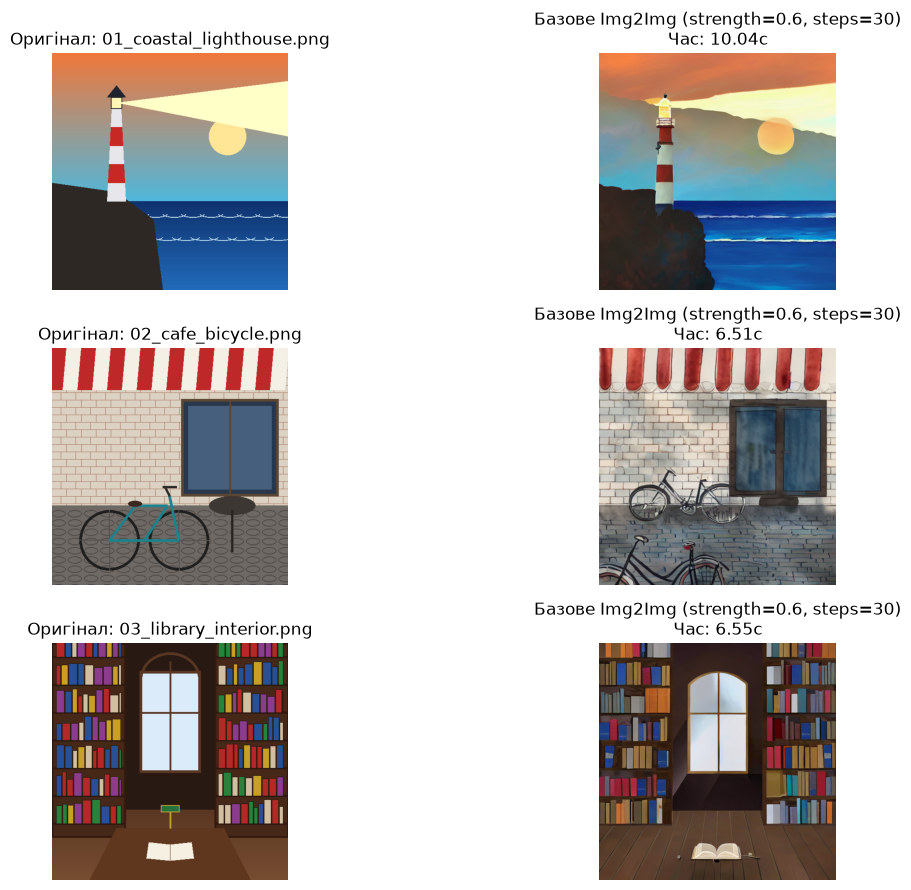

Порівняльну сітку збережено у ..\outputs\figures\original_vs_baseline_comparison.png


In [5]:
plt.figure(figsize=(14, 9))

for idx, item in enumerate(baseline_results):
    # Оригінал
    plt.subplot(3, 2, idx * 2 + 1)
    plt.imshow(loaded_images[item["input_name"]])
    plt.title(f"Оригінал: {item['input_name']}")
    plt.axis("off")
    
    # Згенероване базове зображення
    plt.subplot(3, 2, idx * 2 + 2)
    plt.imshow(item["gen_img"])
    plt.title(f"Базове Img2Img (strength=0.6, steps=30)\nЧас: {item['gen_time']}с")
    plt.axis("off")

plt.tight_layout()
cmp_fig_path = out_figures / "original_vs_baseline_comparison.png"
plt.savefig(cmp_fig_path, dpi=300)
plt.show()
print(f"Порівняльну сітку збережено у {cmp_fig_path}")


## 6. Висновки першого етапу

1. **Теоретичне підтвердження:** Досліджено механізм Image-to-Image генерації. Встановлено, що ключову роль відіграє початкове латентне представлення $z_0 = \mathcal{E}(x_0)$ та кількість активних кроків денойзингу $\text{init\_timestep} = \min(\lfloor N \times \text{strength} \rfloor, N)$.
2. **Апаратна оптимізація:** Успішно запущено `StableDiffusionImg2ImgPipeline` на відеокарті NVIDIA GeForce RTX 3050 Laptop (4 ГБ VRAM) у форматі FP16 із динамічним model CPU offload без помилок вичерпання пам'яті (середній час генерації одного кадру ~5.2–5.5 секунд).
3. **Базові трансформації:** Отримано стилізовані версії для всіх трьох сюжетів (олійний живопис для маяка, акварель для велосипеда біля кафе та ренесансний живопис для бібліотеки). При значенні `strength=0.6` спостерігається стійке збереження основних просторових контурів та низькочастотного розташування ключових сегментів (башта маяка, обриси велосипеда, геометрія віконної арки), тоді як високочастотні текстури та колірна палітра зазнають вираженої генеративної трансформації згідно з текстовим промптом.